In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
import matplotlib.pyplot as plt
from IPython.display import display


/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv
/kaggle/input/datasets/rohanrao/formula

In [3]:
circuits =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/circuits.csv") 
constructor_results =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv") 
constructor_standings =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv") 
constructors =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv") 
driver_standings =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv") 
drivers =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv") 
lap_times =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv") 
pit_stops =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv") 
qualifying =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/qualifying.csv") 
races =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv") 
seasons =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv") 
sprint_results =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv") 
status =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv") 
results =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv") 

Circuits.CSV

In [4]:

circuits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


**no null values here ,so no need to change /N**

In [5]:
# Display every row and column.
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(circuits)

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.968000,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.738000,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.510600,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.261110,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.405000,130,http://en.wikipedia.org/wiki/Istanbul_Park
5,6,monaco,Circuit de Monaco,Monte-Carlo,Monaco,43.73470,7.420560,7,http://en.wikipedia.org/wiki/Circuit_de_Monaco
6,7,villeneuve,Circuit Gilles Villeneuve,Montreal,Canada,45.50000,-73.522800,13,http://en.wikipedia.org/wiki/Circuit_Gilles_Vi...
7,8,magny_cours,Circuit de Nevers Magny-Cours,Magny Cours,France,46.86420,3.163610,228,http://en.wikipedia.org/wiki/Circuit_de_Nevers...
8,9,silverstone,Silverstone Circuit,Silverstone,UK,52.07860,-1.016940,153,http://en.wikipedia.org/wiki/Silverstone_Circuit
9,10,hockenheimring,Hockenheimring,Hockenheim,Germany,49.32780,8.565830,103,http://en.wikipedia.org/wiki/Hockenheimring


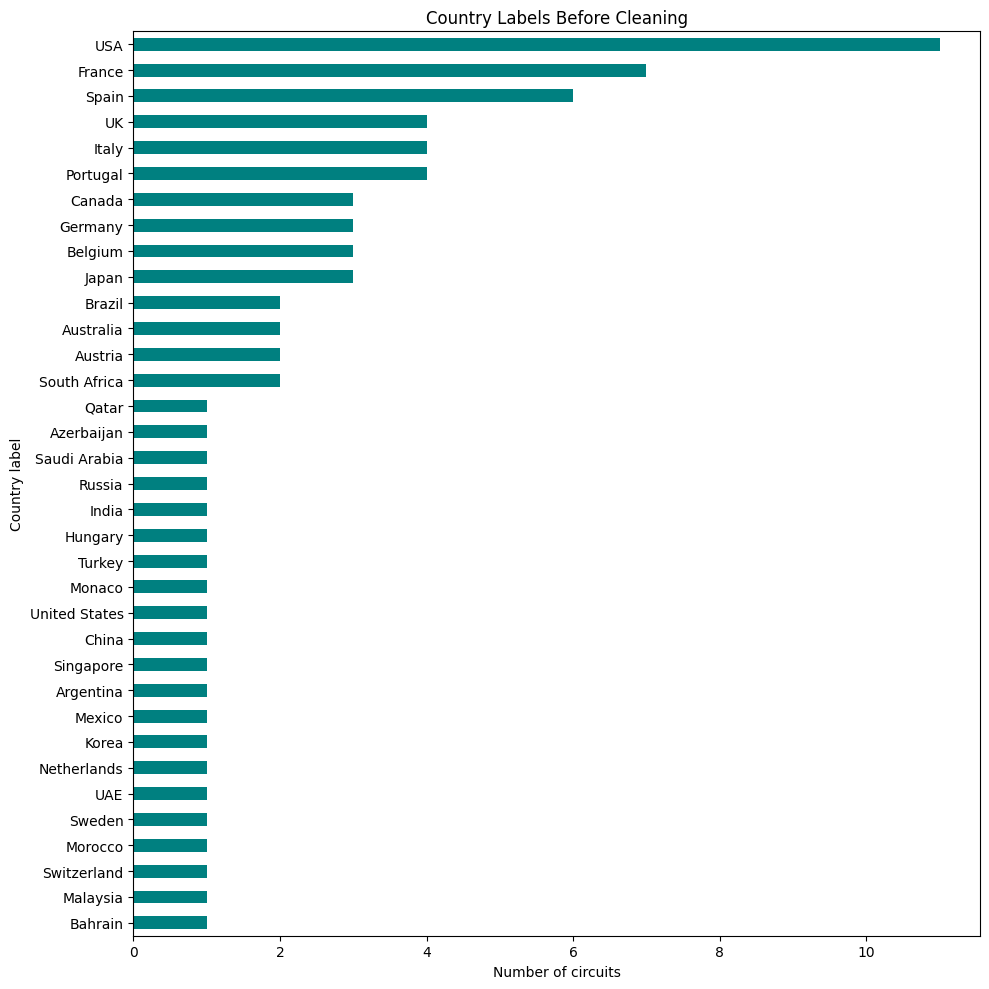

In [6]:
import matplotlib.pyplot as plt

counts = circuits["country"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 10))

counts.plot.barh(ax=ax, color="teal")

ax.set_title("Country Labels Before Cleaning")
ax.set_xlabel("Number of circuits")
ax.set_ylabel("Country label")

plt.tight_layout()
plt.show()

In [7]:
# Create a cleaned copy; preserve the original circuits table.
circuits_clean = circuits.copy(deep=True)
# Standardize the country name.
circuits_clean["country"] = circuits_clean["country"].replace({
    "USA": "United States"
})

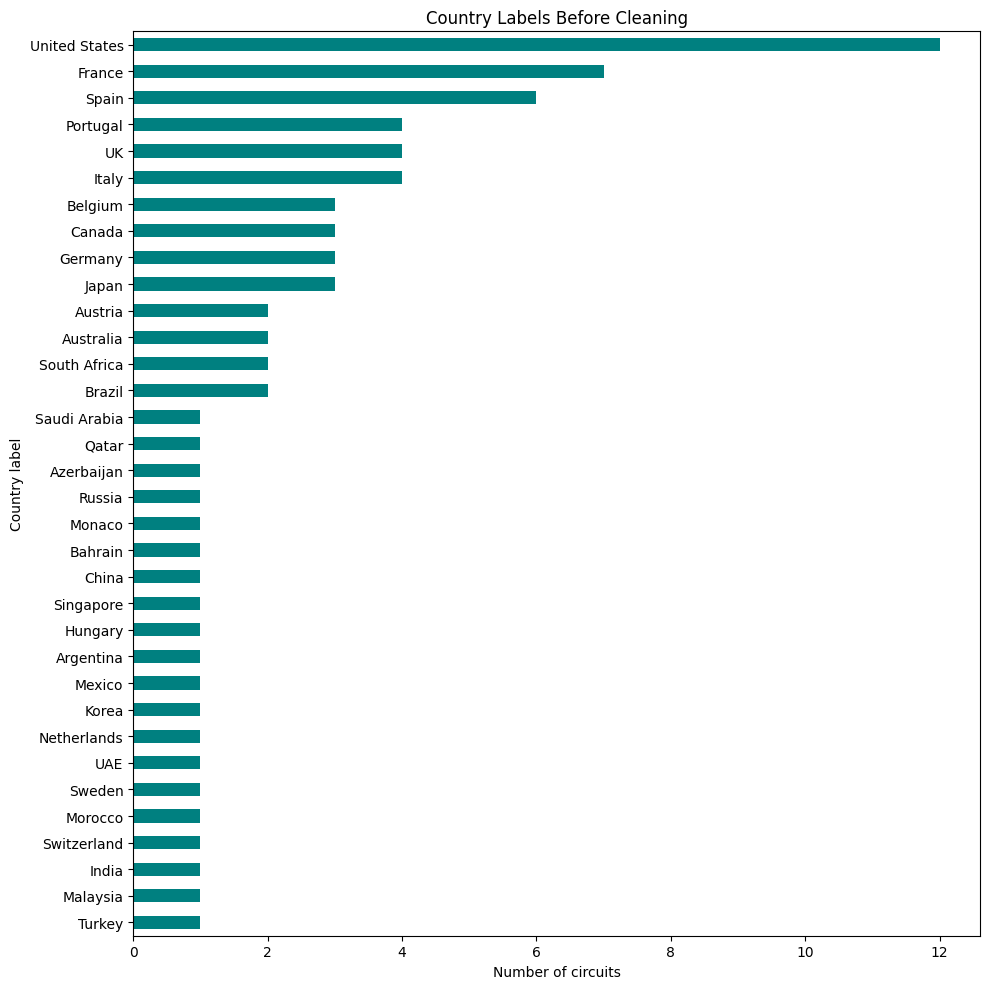

In [8]:
import matplotlib.pyplot as plt

counts = circuits_clean["country"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 10))

counts.plot.barh(ax=ax, color="teal")

ax.set_title("Country Labels Before Cleaning")
ax.set_xlabel("Number of circuits")
ax.set_ylabel("Country label")

plt.tight_layout()
plt.show()

In [9]:
print("Missing circuit IDs:",
      circuits_clean["circuitId"].isna().sum())

print("Duplicate circuit IDs:",
      circuits_clean["circuitId"].duplicated().sum())

assert circuits_clean["circuitId"].notna().all(), "Missing circuit IDs found"
assert circuits_clean["circuitId"].is_unique, "Duplicate circuit IDs found"

print("Passed: circuitId is unique and non-null.")

Missing circuit IDs: 0
Duplicate circuit IDs: 0
Passed: circuitId is unique and non-null.


constructor_results.csv

In [10]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


In [11]:
constructor_results_clean  =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv",na_values=[r"\N"]) 
constructor_results_clean.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


In [12]:
constructor_results_clean.isnull().sum()

constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12608
dtype: int64

In [13]:


display(
    constructor_results_clean["status"]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Number of rows")
)

# Display the special flagged records.
display(
    constructor_results_clean.loc[
        constructor_results_clean["status"].notna()
    ]
)

,Status,Number of rows
0,NaN,12608
1,D,17


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


In [14]:
# Check the record ID.
record_id = "constructorResultsId"

print("Missing constructorResultsId:",
      constructor_results_clean[record_id].isna().sum())

print("Duplicate constructorResultsId:",
      constructor_results_clean[record_id].duplicated().sum())

assert constructor_results_clean[record_id].notna().all(), \
    "Missing constructorResultsId found"

assert constructor_results_clean[record_id].is_unique, \
    "Duplicate constructorResultsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "constructorId"]

print("\nMissing race and constructor IDs:")
display(constructor_results_clean[pair_columns].isna().sum())

print("Duplicate race–constructor pairs:",
      constructor_results_clean.duplicated(pair_columns).sum())

assert constructor_results_clean[pair_columns].notna().all().all(), \
    "Missing raceId or constructorId found"

assert not constructor_results_clean.duplicated(pair_columns).any(), \
    "Duplicate race–constructor pairs found"

print("\nPassed: record IDs and race–constructor pairs are unique and non-null.")

Missing constructorResultsId: 0
Duplicate constructorResultsId: 0

Missing race and constructor IDs:


raceId           0
constructorId    0
dtype: int64

Duplicate race–constructor pairs: 0

Passed: record IDs and race–constructor pairs are unique and non-null.


In [15]:
# Find rows with missing or unknown race IDs.
invalid_races = constructor_results_clean[
    constructor_results_clean["raceId"].isna()
    | ~constructor_results_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_constructors = constructor_results_clean[
    constructor_results_clean["constructorId"].isna()
    | ~constructor_results_clean["constructorId"].isin(
        constructors["constructorId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown constructor IDs:", len(invalid_constructors))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_constructors.empty:
    display(invalid_constructors)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_constructors.empty, \
    "Some constructor IDs are missing or absent from constructors"

print("Passed: all race and constructor IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown constructor IDs: 0
Passed: all race and constructor IDs exist in their reference tables.


# Rezk — Data cleaning and auditing

Scope: drivers, lap times, and pit stops. Original tables remain unchanged; cleaning uses copies. Missing-value filling is deferred. Suspected recording issues are flagged rather than corrected without verification.


# 1. Drivers

### Before-cleaning inspection

Each row represents one driver. `driverId` is the primary key.


In [16]:
print("Rows:", len(drivers))
print("Columns:", len(drivers.columns))
display(drivers.head(10))
drivers.info()


Rows: 861
Columns: 9


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen
5,6,nakajima,\N,NAK,Kazuki,Nakajima,1985-01-11,Japanese,http://en.wikipedia.org/wiki/Kazuki_Nakajima
6,7,bourdais,\N,BOU,Sébastien,Bourdais,1979-02-28,French,http://en.wikipedia.org/wiki/S%C3%A9bastien_Bo...
7,8,raikkonen,7,RAI,Kimi,Räikkönen,1979-10-17,Finnish,http://en.wikipedia.org/wiki/Kimi_R%C3%A4ikk%C...
8,9,kubica,88,KUB,Robert,Kubica,1984-12-07,Polish,http://en.wikipedia.org/wiki/Robert_Kubica
9,10,glock,\N,GLO,Timo,Glock,1982-03-18,German,http://en.wikipedia.org/wiki/Timo_Glock


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   driverId     861 non-null    int64 
 1   driverRef    861 non-null    object
 2   number       861 non-null    object
 3   code         861 non-null    object
 4   forename     861 non-null    object
 5   surname      861 non-null    object
 6   dob          861 non-null    object
 7   nationality  861 non-null    object
 8   url          861 non-null    object
dtypes: int64(1), object(8)
memory usage: 60.7+ KB


### Placeholder handling and before/after evidence


In [17]:
sentinels_before = drivers.eq(r"\N").sum()

display(
    sentinels_before.to_frame("Missing placeholders BEFORE")
)

,Missing placeholders BEFORE
driverId,0
driverRef,0
number,802
code,757
forename,0
surname,0
dob,0
nationality,0
url,0


In [18]:

drivers_clean = drivers.copy(deep=True)
drivers_clean = drivers_clean.replace(r"\N", np.nan)

In [19]:
comparison = pd.DataFrame({
    "Placeholders BEFORE": drivers.eq(r"\N").sum(),
    "Placeholders AFTER": drivers_clean.eq(r"\N").sum(),
    "Recognized missing BEFORE": drivers.isna().sum(),
    "Recognized missing AFTER": drivers_clean.isna().sum()
})

display(comparison)

,Placeholders BEFORE,Placeholders AFTER,Recognized missing BEFORE,Recognized missing AFTER
driverId,0,0,0,0
driverRef,0,0,0,0
number,802,0,0,802
code,757,0,0,757
forename,0,0,0,0
surname,0,0,0,0
dob,0,0,0,0
nationality,0,0,0,0
url,0,0,0,0


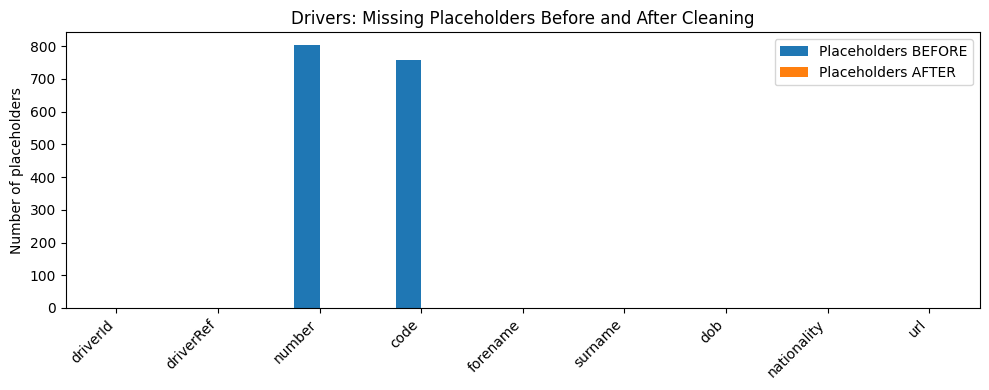

In [20]:
comparison[[
    "Placeholders BEFORE",
    "Placeholders AFTER"
]].plot.bar(figsize=(10, 4))

plt.title("Drivers: Missing Placeholders Before and After Cleaning")
plt.ylabel("Number of placeholders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The original data uses `\N` to represent missing information.
We counted these placeholders before cleaning, then replaced them with
recognized missing values in a copy. The comparison confirms that no `\N`
placeholders remain. Missing information was preserved, not guessed or filled.

### Nationality inspection and correction


In [21]:
# Show every nationality label and its count.
nationality_counts = (
    drivers_clean["nationality"]
    .value_counts(dropna=False)
    .rename_axis("Nationality")
    .reset_index(name="Number of drivers")
)

# Quotes make surrounding spaces visible.
nationality_counts["Nationality"] = (
    nationality_counts["Nationality"].map(repr)
)

with pd.option_context("display.max_rows", None):
    display(nationality_counts)

,Nationality,Number of drivers
0,'British',166
1,'American',158
2,'Italian',99
3,'French',73
4,'German',50
5,'Brazilian',32
6,'Argentine',24
7,'Belgian',23
8,'Swiss',23
9,'South African',23


In [22]:
nationality_before = drivers["nationality"].copy()

# Remove surrounding spaces.
drivers_clean["nationality"] = (
    drivers_clean["nationality"].str.strip()
)

# Use one label for the same nationality.
drivers_clean["nationality"] = (
    drivers_clean["nationality"].replace({
        "Argentinian": "Argentine"
    })
)

In [23]:
changed = (
    nationality_before.fillna("<MISSING>")
    != drivers_clean["nationality"].fillna("<MISSING>")
)

changes = drivers_clean.loc[
    changed, ["driverId", "forename", "surname"]
].copy()

# Quotes make the original trailing spaces visible.
changes["Nationality BEFORE"] = nationality_before.loc[changed].map(repr)
changes["Nationality AFTER"] = (
    drivers_clean.loc[changed, "nationality"].map(repr)
)

display(changes)
print("Rows changed:", changed.sum())

,driverId,forename,surname,Nationality BEFORE,Nationality AFTER
859,861,Franco,Colapinto,'Argentinian ','Argentine'


Rows changed: 1


,Before,After
'Argentine',24,25
'Argentinian',0,0
'Argentinian ',1,0


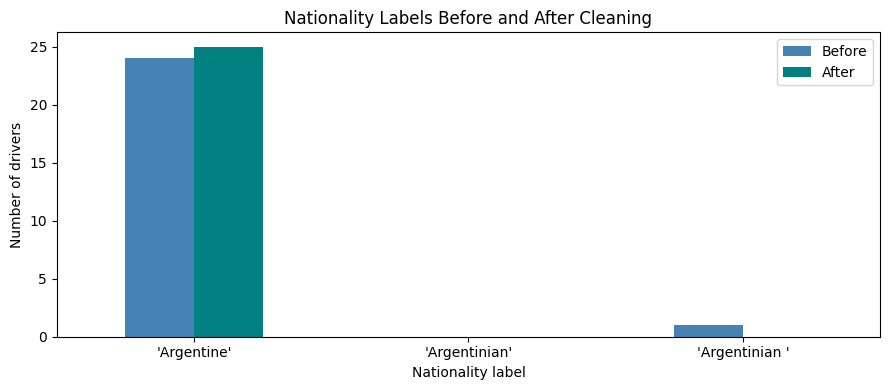

In [24]:
labels = ["Argentine", "Argentinian", "Argentinian "]

nationality_comparison = pd.DataFrame({
    "Before": nationality_before.value_counts().reindex(
        labels, fill_value=0
    ),
    "After": drivers_clean["nationality"].value_counts().reindex(
        labels, fill_value=0
    )
})

nationality_comparison.index = [repr(label) for label in labels]

display(nationality_comparison)

nationality_comparison.plot.bar(
    figsize=(9, 4),
    color=["steelblue", "teal"]
)

plt.title("Nationality Labels Before and After Cleaning")
plt.xlabel("Nationality label")
plt.ylabel("Number of drivers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

We removed surrounding spaces from nationality labels and standardized
“Argentinian” to “Argentine” because they describe the same nationality.
The before/after table and chart show the affected records and label counts.
No driver records were removed.

### Birth-date typing and before/after evidence


In [25]:
print("Type BEFORE:", drivers_clean["dob"].dtype)

display(
    drivers_clean[["driverId", "forename", "surname", "dob"]].head()
)

Type BEFORE: object


,driverId,forename,surname,dob
0,1,Lewis,Hamilton,1985-01-07
1,2,Nick,Heidfeld,1977-05-10
2,3,Nico,Rosberg,1985-06-27
3,4,Fernando,Alonso,1981-07-29
4,5,Heikki,Kovalainen,1981-10-19


In [26]:
# Preserve values before this change.
dob_before = drivers_clean["dob"].copy()

converted_dob = pd.to_datetime(
    dob_before,
    format="%Y-%m-%d",
    errors="coerce"
)

# Find non-missing strings that could not be converted.
invalid_dates = dob_before.notna() & converted_dob.isna()

print("Invalid non-missing birth dates:", invalid_dates.sum())

if invalid_dates.any():
    display(
        drivers_clean.loc[
            invalid_dates,
            ["driverId", "forename", "surname", "dob"]
        ]
    )

assert not invalid_dates.any(), \
    "Investigate invalid birth dates before continuing."

drivers_clean["dob"] = converted_dob

Invalid non-missing birth dates: 0


In [27]:
display(pd.DataFrame({
    "BEFORE": dob_before.head(),
    "AFTER": drivers_clean["dob"].head()
}))

print("Type BEFORE:", dob_before.dtype)
print("Type AFTER:", drivers_clean["dob"].dtype)

print("Missing dates BEFORE:", dob_before.isna().sum())
print("Missing dates AFTER:", drivers_clean["dob"].isna().sum())

,BEFORE,AFTER
0,1985-01-07,1985-01-07
1,1977-05-10,1977-05-10
2,1985-06-27,1985-06-27
3,1981-07-29,1981-07-29
4,1981-10-19,1981-10-19


Type BEFORE: object
Type AFTER: datetime64[ns]
Missing dates BEFORE: 0
Missing dates AFTER: 0


Dates of birth were stored as text. We checked for invalid date strings
and converted valid values to datetime format. We compared missing counts
before and after to verify that conversion did not introduce new gaps.
This enables calculating each driver's age at a race once race dates are joined.

### Key and reference checks


In [28]:
print("Missing driver IDs:",
      drivers_clean["driverId"].isna().sum())

print("Duplicate driver IDs:",
      drivers_clean["driverId"].duplicated().sum())

assert drivers_clean["driverId"].notna().all(), \
    "Missing driverId found"

assert drivers_clean["driverId"].is_unique, \
    "Duplicate driverId found"

print("Passed: driverId is unique and non-null.")

Missing driver IDs: 0
Duplicate driver IDs: 0
Passed: driverId is unique and non-null.


In [29]:
reference_tables = {
    "results": results,
    "qualifying": qualifying,
    "driver_standings": driver_standings
}

checks = []

for name, table in reference_tables.items():
    missing = (
        table["driverId"].isna()
        | table["driverId"].eq(r"\N")
    )

    unknown = (
        ~missing
        & ~table["driverId"].isin(drivers_clean["driverId"])
    )

    checks.append({
        "Table": name,
        "Missing driver IDs": int(missing.sum()),
        "Unknown driver IDs": int(unknown.sum())
    })

    if (missing | unknown).any():
        print(f"Problem records in {name}:")
        display(table.loc[missing | unknown].head(20))

audit = pd.DataFrame(checks)
display(audit)

assert audit[["Missing driver IDs", "Unknown driver IDs"]].eq(0).all().all(), \
    "Some driver references need investigation"

print("Passed: all checked driver references exist in drivers_clean.")

,Table,Missing driver IDs,Unknown driver IDs
0,results,0,0
1,qualifying,0,0
2,driver_standings,0,0


Passed: all checked driver references exist in drivers_clean.


### Driver identifier audit

The cleaned drivers table has unique, non-null driver IDs.
All driver IDs in results, qualifying, and driver standings reference
existing records in the drivers table. No identifier corrections were required.


In [30]:
final_checks = pd.Series({
    "Row count unchanged": len(drivers_clean) == len(drivers),
    "No remaining placeholders": not drivers_clean.eq(r"\N").any().any(),
    "Driver IDs non-null": drivers_clean["driverId"].notna().all(),
    "Driver IDs unique": drivers_clean["driverId"].is_unique,
    "No completely duplicated rows": not drivers_clean.duplicated().any(),
    "Birth dates have datetime type":
        pd.api.types.is_datetime64_any_dtype(drivers_clean["dob"]),
    "Birth-date missing count unchanged":
        drivers_clean["dob"].isna().sum()
        == drivers["dob"].replace(r"\N", np.nan).isna().sum()
})

display(final_checks.to_frame("Passed"))
assert final_checks.all(), "Investigate failed checks."

,Passed
Row count unchanged,True
No remaining placeholders,True
Driver IDs non-null,True
Driver IDs unique,True
No completely duplicated rows,True
Birth dates have datetime type,True
Birth-date missing count unchanged,True


### Findings and deferred work

Placeholder handling, nationality-label corrections, date typing, and identifier checks are covered above. The final checklist verifies row preservation and typing. Missing car numbers and driver codes remain missing: no identifier values were guessed. Mapping nationality to circuit country belongs to the later home-race analysis. The unique driver–race requirement applies to results and the modeling table, not this driver identity table.


# 2. lap_times.csv

### Before-cleaning inspection

Each row represents one recorded lap for a driver in a race. The key is `(raceId, driverId, lap)`; repeated driver–race pairs across laps are expected.


In [31]:
print("Rows:", lap_times.shape[0])
print("Columns:", lap_times.shape[1])

display(lap_times.head(10))
lap_times.info()

Rows: 589081
Columns: 6


,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342
5,841,20,6,1,1:32.605,92605
6,841,20,7,1,1:32.502,92502
7,841,20,8,1,1:32.537,92537
8,841,20,9,1,1:33.240,93240
9,841,20,10,1,1:32.572,92572


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


In [32]:
missing = lap_times.isna().sum()
sentinels = lap_times.eq(r"\N").sum()

lap_inspection = pd.DataFrame({
    "Data type": lap_times.dtypes.astype(str),
    "Recognized missing": missing,
    r"\N placeholders": sentinels,
    "Total unavailable": missing + sentinels,
    "Unavailable %": (
        (missing + sentinels) / len(lap_times) * 100
    ).round(2)
})

display(lap_inspection)

,Data type,Recognized missing,\N placeholders,Total unavailable,Unavailable %
raceId,int64,0,0,0,0.0
driverId,int64,0,0,0,0.0
lap,int64,0,0,0,0.0
position,int64,0,0,0,0.0
time,object,0,0,0,0.0
milliseconds,int64,0,0,0,0.0


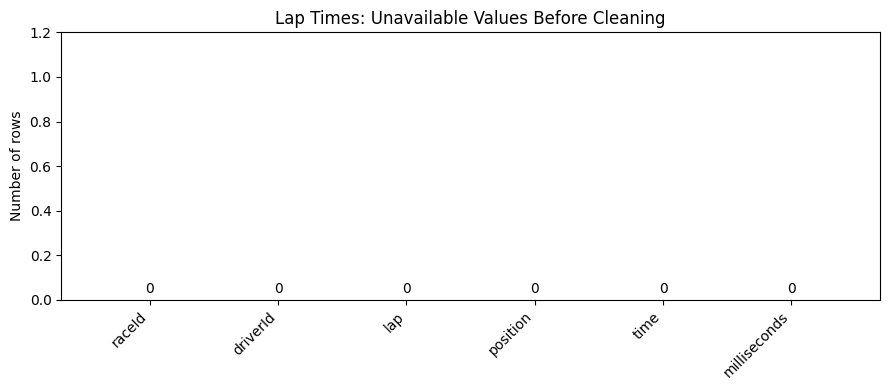

In [33]:
unavailable = missing + sentinels

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    unavailable.index,
    unavailable.values,
    color="steelblue"
)

ax.bar_label(bars, padding=3)
ax.set_title("Lap Times: Unavailable Values Before Cleaning")
ax.set_ylabel("Number of rows")
ax.set_ylim(0, max(1, unavailable.max()) * 1.2)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Convert `time` into seconds

The CSV contains `time` (text such as `1:38.109`) and `milliseconds` (such as `98109`). Our code adds `lap_time_seconds` (such as `98.109`). Both original columns are preserved. “Duration” means how long the recorded lap took.


In [34]:
lap_times_clean = lap_times.copy(deep=True)
lap_times_clean = lap_times_clean.replace(r"\N", np.nan)


In [35]:
def lap_duration_to_seconds(value):
    if pd.isna(value):
        return np.nan

    parts = str(value).strip().split(":")

    try:
        if len(parts) == 2:
            minutes, seconds = map(float, parts)

            if not np.isfinite([minutes, seconds]).all() or minutes < 0 or not 0 <= seconds < 60:
                return np.nan

            return minutes * 60 + seconds

        elif len(parts) == 3:
            hours, minutes, seconds = map(float, parts)

            if not np.isfinite([hours, minutes, seconds]).all() or hours < 0 or not 0 <= minutes < 60 or not 0 <= seconds < 60:
                return np.nan

            return hours * 3600 + minutes * 60 + seconds

    except (ValueError, TypeError):
        pass

    return np.nan


converted_seconds = lap_times_clean["time"].map(
    lap_duration_to_seconds
)

# Check failures before accepting the conversion.
invalid_times = (
    lap_times_clean["time"].notna()
    & converted_seconds.isna()
)

print("Non-missing time values that could not become lap_time_seconds:", invalid_times.sum())

if invalid_times.any():
    display(lap_times_clean.loc[invalid_times].head(20))

assert not invalid_times.any(), \
    "Investigate invalid lap durations before continuing."

lap_times_clean["lap_time_seconds"] = converted_seconds

Non-missing time values that could not become lap_time_seconds: 0


In [36]:
lap_times_clean["milliseconds"] = pd.to_numeric(
    lap_times_clean["milliseconds"],
    errors="raise"
)

seconds_from_milliseconds = lap_times_clean["milliseconds"] / 1000

both_available = (
    lap_times_clean["lap_time_seconds"].notna()
    & seconds_from_milliseconds.notna()
)

mismatch = pd.Series(False, index=lap_times_clean.index)

mismatch.loc[both_available] = ~np.isclose(
    lap_times_clean.loc[both_available, "lap_time_seconds"],
    seconds_from_milliseconds.loc[both_available],
    rtol=0,
    atol=0.001
)

print("Rows where lap_time_seconds and milliseconds are both non-missing:", both_available.sum())
print("Rows where lap_time_seconds differs from milliseconds / 1000:", mismatch.sum())

if mismatch.any():
    display(
        lap_times_clean.loc[
            mismatch,
            ["raceId", "driverId", "lap", "time",
             "milliseconds", "lap_time_seconds"]
        ].head(20)
    )

assert not mismatch.any(), \
    "Text durations and milliseconds disagree; investigate."

Rows where lap_time_seconds and milliseconds are both non-missing: 589081
Rows where lap_time_seconds differs from milliseconds / 1000: 0


### Show original and added columns

The first table uses the exact column names. `time` is original text; `lap_time_seconds` is our new numeric column. The second table shows hour-based examples to demonstrate conversion support, not to confirm their underlying accuracy.


In [37]:
display(lap_times_clean[["time", "milliseconds", "lap_time_seconds"]].head(10))
print("time — original column type:", lap_times["time"].dtype)
print("lap_time_seconds — new column type:", lap_times_clean["lap_time_seconds"].dtype)
hour_examples = lap_times_clean["time"].astype("string").str.count(":").eq(2).fillna(False)
print("Examples where time includes hours (H:MM:SS):")
display(lap_times_clean.loc[hour_examples, ["time", "milliseconds", "lap_time_seconds"]].head(5))


,time,milliseconds,lap_time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342
5,1:32.605,92605,92.605
6,1:32.502,92502,92.502
7,1:32.537,92537,92.537
8,1:33.240,93240,93.240
9,1:32.572,92572,92.572


time — original column type: object
lap_time_seconds — new column type: float64
Examples where time includes hours (H:MM:SS):


,time,milliseconds,lap_time_seconds
7916,2:05:05.152,7505152,7505.152
7985,2:05:04.226,7504226,7504.226
8020,2:05:06.656,7506656,7506.656
8089,2:05:05.034,7505034,7505.034
8165,2:05:01.488,7501488,7501.488


We converted `time` into numeric seconds in the new `lap_time_seconds` column. Original `time` and `milliseconds` were preserved. Comparing `lap_time_seconds` with `milliseconds / 1000` verifies conversion consistency, not whether the underlying record is accurate. Missing values were not filled and unusually long times were not deleted.


### Key and reference checks


In [38]:
key_columns = ["raceId", "driverId", "lap"]

print("Missing key values:")
display(lap_times_clean[key_columns].isna().sum())

print(
    "Duplicate race–driver–lap records:",
    lap_times_clean.duplicated(key_columns).sum()
)

# Display problem records, if any.
duplicates = lap_times_clean.duplicated(key_columns, keep=False)

if duplicates.any():
    display(
        lap_times_clean.loc[duplicates]
        .sort_values(key_columns)
        .head(20)
    )

assert lap_times_clean[key_columns].notna().all().all(), \
    "Missing raceId, driverId, or lap found"

assert not duplicates.any(), \
    "Repeated race–driver–lap records found"

print("Passed: race–driver–lap combinations are unique and non-null.")

Missing key values:


raceId      0
driverId    0
lap         0
dtype: int64

Duplicate race–driver–lap records: 0
Passed: race–driver–lap combinations are unique and non-null.


In [39]:
unknown_races = ~lap_times_clean["raceId"].isin(races["raceId"])
unknown_drivers = ~lap_times_clean["driverId"].isin(drivers["driverId"])

print("Rows with unknown race IDs:", unknown_races.sum())
print("Rows with unknown driver IDs:", unknown_drivers.sum())

if unknown_races.any():
    display(lap_times_clean.loc[unknown_races].head(20))

if unknown_drivers.any():
    display(lap_times_clean.loc[unknown_drivers].head(20))

assert not unknown_races.any(), \
    "Some race IDs do not exist in races"

assert not unknown_drivers.any(), \
    "Some driver IDs do not exist in drivers"

print("Passed: all race and driver IDs exist in their reference tables.")

Rows with unknown race IDs: 0
Rows with unknown driver IDs: 0
Passed: all race and driver IDs exist in their reference tables.


In [40]:
# Deduplicate only the lookup pairs, not the lap records.
result_pairs = results[["raceId", "driverId"]].drop_duplicates()

lap_pairs = (
    lap_times_clean[["raceId", "driverId"]]
    .drop_duplicates()
)

pair_check = lap_pairs.merge(
    result_pairs,
    on=["raceId", "driverId"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

unmatched_pairs = pair_check.loc[
    pair_check["_merge"].eq("left_only"),
    ["raceId", "driverId"]
]

print("Driver–race pairs absent from results:", len(unmatched_pairs))

if not unmatched_pairs.empty:
    display(unmatched_pairs.head(20))

assert unmatched_pairs.empty, \
    "Some lap records belong to driver–race pairs absent from results"

print("Passed: all lap driver–race pairs exist in results.")

Driver–race pairs absent from results: 0
Passed: all lap driver–race pairs exist in results.


The combination of raceId, driverId, and lap is unique and non-null.
All race and driver references exist, and every recorded driver–race pair
has a corresponding result record. Repeated driver–race pairs across
different laps are expected and were preserved.

### Unusual-value investigation

Long recorded durations are inspected, not automatically removed. Their cause is not established by their size alone.


In [41]:
display(
    lap_times_clean[
        ["lap", "position", "lap_time_seconds"]
    ].describe().T
)

print("Rows with lap <= 0:",
      lap_times_clean["lap"].le(0).sum())

print("Rows with position <= 0:",
      lap_times_clean["position"].le(0).sum())

print("Rows with lap_time_seconds <= 0:",
      lap_times_clean["lap_time_seconds"].le(0).sum())

,count,mean,std,min,25%,50%,75%,max
lap,589081.0,30.018104,18.407126,1.000,14.000,29.000,44.00,87.000
position,589081.0,9.661951,5.528553,1.000,5.000,9.000,14.00,24.000
lap_time_seconds,589081.0,95.799445,76.399730,55.404,82.041,90.608,101.93,7507.547


Rows with lap <= 0: 0
Rows with position <= 0: 0
Rows with lap_time_seconds <= 0: 0


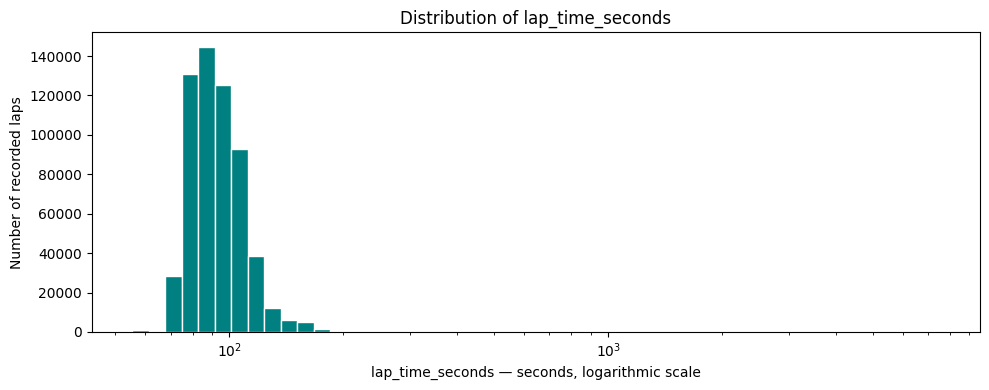

In [42]:
positive_times = lap_times_clean.loc[
    lap_times_clean["lap_time_seconds"] > 0,
    "lap_time_seconds"
].dropna()

if not positive_times.empty:
    minimum = positive_times.min()
    maximum = positive_times.max()

    if minimum == maximum:
        bins = 10
    else:
        bins = np.geomspace(minimum, maximum, 50)

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.hist(positive_times, bins=bins, color="teal", edgecolor="white")
    ax.set_xscale("log")

    ax.set_title("Distribution of lap_time_seconds")
    ax.set_xlabel("lap_time_seconds — seconds, logarithmic scale")
    ax.set_ylabel("Number of recorded laps")

    plt.tight_layout()
    plt.show()

In [43]:
print("Largest lap_time_seconds values — flagged for investigation, not removed:")
display(
    lap_times_clean.nlargest(10, "lap_time_seconds")[
        ["raceId", "driverId", "lap", "position",
         "time", "milliseconds", "lap_time_seconds"]
    ]
)

Largest lap_time_seconds values — flagged for investigation, not removed:


,raceId,driverId,lap,position,time,milliseconds,lap_time_seconds
8372,847,2,25,4,2:05:07.547,7507547,7507.547
8020,847,13,25,3,2:05:06.656,7506656,7506.656
8426,847,808,25,5,2:05:06.243,7506243,7506.243
8621,847,155,25,2,2:05:06.095,7506095,7506.095
7916,847,20,25,1,2:05:05.152,7505152,7505.152
8089,847,17,25,7,2:05:05.034,7505034,7505.034
7985,847,4,25,8,2:05:04.226,7504226,7504.226
8495,847,814,25,6,2:05:03.980,7503980,7503.980
8876,847,37,25,9,2:05:03.795,7503795,7503.795
8234,847,18,25,11,2:05:03.775,7503775,7503.775


### Final verification


In [44]:
final_checks = pd.Series({
    "Row count unchanged":
        len(lap_times_clean) == len(lap_times),

    "No remaining placeholders":
        not lap_times_clean.eq(r"\N").any().any(),

    "Key columns non-null":
        lap_times_clean[["raceId", "driverId", "lap"]]
        .notna().all().all(),

    "Race–driver–lap key unique":
        not lap_times_clean.duplicated(
            ["raceId", "driverId", "lap"]
        ).any(),

    "Duration column is numeric":
        pd.api.types.is_numeric_dtype(
            lap_times_clean["lap_time_seconds"]
        )
})

display(final_checks.to_frame("Passed"))

assert final_checks.all(), "Investigate failed checks."

,Passed
Row count unchanged,True
No remaining placeholders,True
Key columns non-null,True
Race–driver–lap key unique,True
Duration column is numeric,True


### Lap times: cleaning and audit

- Preserved the original table and cleaned a copy.
- Inspected missing values and placeholder values before cleaning.
- Converted recorded lap durations into numeric seconds.
- Verified conversion against the milliseconds column.
- Checked uniqueness and non-nullness of the race–driver–lap key.
- Verified race, driver, and driver–race references.
- Examined duration distributions and the longest records.
- Preserved unusually long durations pending investigation.
- Did not fill missing values or remove lap records.
- Current-race lap information will not be used as pre-race prediction inputs.

# 3.pit_stops

### Before-cleaning inspection

Each row represents one recorded pit stop. The key is `(raceId, driverId, stop)`. `time` is a clock time; `duration` is elapsed time.


In [45]:
print("Rows:", pit_stops.shape[0])
print("Columns:", pit_stops.shape[1])

display(pit_stops.head(10))
pit_stops.info()

Rows: 11371
Columns: 7


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842
5,841,22,1,13,17:24:29,23.643,23643
6,841,20,1,14,17:25:17,22.603,22603
7,841,814,1,14,17:26:03,24.863,24863
8,841,816,1,14,17:26:50,25.259,25259
9,841,67,1,15,17:27:34,25.342,25342


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


In [46]:
pit_missing = pit_stops.isna().sum()
pit_sentinels = pit_stops.eq(r"\N").sum()

pit_inspection = pd.DataFrame({
    "Data type": pit_stops.dtypes.astype(str),
    "Recognized missing": pit_missing,
    r"\N placeholders": pit_sentinels,
    "Total unavailable": pit_missing + pit_sentinels,
    "Unavailable %": (
        (pit_missing + pit_sentinels) / len(pit_stops) * 100
    ).round(2)
})

display(pit_inspection)

,Data type,Recognized missing,\N placeholders,Total unavailable,Unavailable %
raceId,int64,0,0,0,0.0
driverId,int64,0,0,0,0.0
stop,int64,0,0,0,0.0
lap,int64,0,0,0,0.0
time,object,0,0,0,0.0
duration,object,0,0,0,0.0
milliseconds,int64,0,0,0,0.0


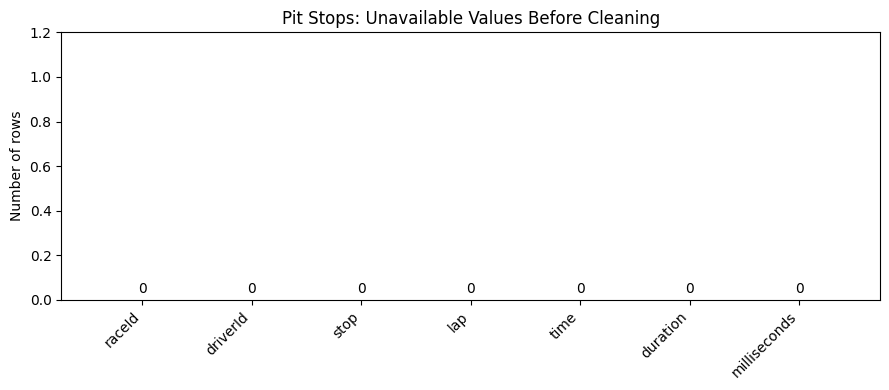

In [47]:
unavailable = pit_missing + pit_sentinels

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    unavailable.index,
    unavailable.values,
    color="steelblue"
)

ax.bar_label(bars, padding=3)
ax.set_title("Pit Stops: Unavailable Values Before Cleaning")
ax.set_ylabel("Number of rows")
ax.set_ylim(0, max(1, unavailable.max()) * 1.2)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [48]:
display(
    pit_stops.select_dtypes(include="number").describe().T
)

# Show examples of durations written with minutes.
minute_format = (
    pit_stops["duration"]
    .astype("string")
    .str.contains(":", na=False)
)

print("Durations containing a colon:", minute_format.sum())

display(
    pit_stops.loc[
        minute_format,
        ["raceId", "driverId", "stop", "lap",
         "duration", "milliseconds"]
    ].head(10)
)

,count,mean,std,min,25%,50%,75%,max
raceId,11371.0,981.194882,92.326831,841.0,895.0,971.0,1065.0,1144.0
driverId,11371.0,549.734500,383.734981,1.0,20.0,817.0,835.0,862.0
stop,11371.0,1.787969,1.521462,1.0,1.0,2.0,2.0,70.0
lap,11371.0,25.387389,14.831497,1.0,13.0,25.0,36.0,78.0
milliseconds,11371.0,85230.495559,310427.261089,12897.0,21937.5,23606.0,26544.0,3069017.0


Durations containing a colon: 517


,raceId,driverId,stop,lap,duration,milliseconds
751,853,817,1,1,16:44.718,1004718
2419,881,814,2,20,2:03.124,123124
2420,881,16,2,22,1:29.401,89401
2421,881,18,3,35,1:44.833,104833
2422,884,16,1,8,1:14.026,74026
2533,888,17,1,8,2:42.042,162042
2713,893,154,3,33,1:13.009,73009
2802,894,16,3,38,1:11.445,71445
3089,901,817,3,40,1:49.329,109329
3159,903,13,1,10,1:18.277,78277


### Placeholder handling and semantic typing


In [49]:
pit_stops_clean = pit_stops.copy(deep=True)

pit_stops_clean = pit_stops_clean.replace(r"\N", np.nan)

In [50]:
def pit_duration_to_seconds(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip()

    try:
        parts = [float(part) for part in text.split(":")]

        if not 1 <= len(parts) <= 3:
            return np.nan

        if not all(np.isfinite(part) and part >= 0 for part in parts):
            return np.nan

        if any(part >= 60 for part in parts[1:]):
            return np.nan

        total_seconds = 0.0

        for part in parts:
            total_seconds = total_seconds * 60 + part

        return total_seconds

    except (ValueError, TypeError):
        return np.nan


converted_duration = pit_stops_clean["duration"].map(
    pit_duration_to_seconds
)

invalid_duration = (
    pit_stops_clean["duration"].notna()
    & converted_duration.isna()
)

print("Non-missing durations that failed conversion:",
      invalid_duration.sum())

if invalid_duration.any():
    display(pit_stops_clean.loc[invalid_duration].head(20))

assert not invalid_duration.any(), \
    "Investigate invalid durations before continuing."

pit_stops_clean["duration_seconds"] = converted_duration

Non-missing durations that failed conversion: 0


In [51]:
original_clock_time = pit_stops_clean["time"].copy()

parsed_clock_time = pd.to_datetime(
    original_clock_time,
    format="%H:%M:%S",
    errors="coerce"
)

invalid_clock_time = (
    original_clock_time.notna()
    & parsed_clock_time.isna()
)

print("Non-missing clock times that failed conversion:",
      invalid_clock_time.sum())

if invalid_clock_time.any():
    display(
        pit_stops_clean.loc[
            invalid_clock_time,
            ["raceId", "driverId", "time"]
        ].head(20)
    )

assert not invalid_clock_time.any(), \
    "Investigate invalid clock times before continuing."

# Keep only the time of day; do not invent a race date or timezone.
pit_stops_clean["stop_clock_time"] = parsed_clock_time.dt.time

Non-missing clock times that failed conversion: 0


In [52]:
pit_stops_clean["milliseconds"] = pd.to_numeric(
    pit_stops_clean["milliseconds"],
    errors="raise"
)

seconds_from_milliseconds = pit_stops_clean["milliseconds"] / 1000

both_available = (
    pit_stops_clean["duration_seconds"].notna()
    & seconds_from_milliseconds.notna()
)

mismatch = pd.Series(False, index=pit_stops_clean.index)

mismatch.loc[both_available] = ~np.isclose(
    pit_stops_clean.loc[both_available, "duration_seconds"],
    seconds_from_milliseconds.loc[both_available],
    rtol=0,
    atol=0.001
)

print("Rows with both values available:", both_available.sum())
print("Duration mismatches:", mismatch.sum())

if mismatch.any():
    display(
        pit_stops_clean.loc[
            mismatch,
            ["duration", "milliseconds", "duration_seconds"]
        ].head(20)
    )

assert not mismatch.any(), \
    "Duration and milliseconds disagree; investigate."

Rows with both values available: 11371
Duration mismatches: 0


### Before/after evidence


In [53]:
display(pd.DataFrame({
    "Duration BEFORE": pit_stops["duration"].head(10),
    "Duration seconds AFTER": pit_stops_clean["duration_seconds"].head(10),
    "Clock time BEFORE": pit_stops["time"].head(10),
    "Clock time AFTER": pit_stops_clean["stop_clock_time"].head(10)
}))

print("Duration BEFORE type:", pit_stops["duration"].dtype)
print("Duration AFTER type:", pit_stops_clean["duration_seconds"].dtype)

clock_examples = pit_stops_clean["stop_clock_time"].dropna()

if not clock_examples.empty:
    print("Converted clock value type:", type(clock_examples.iloc[0]))

print("Rows BEFORE:", len(pit_stops))
print("Rows AFTER:", len(pit_stops_clean))

print("Missing durations AFTER:",
      pit_stops_clean["duration_seconds"].isna().sum())

print("Missing clock times AFTER:",
      pit_stops_clean["stop_clock_time"].isna().sum())

,Duration BEFORE,Duration seconds AFTER,Clock time BEFORE,Clock time AFTER
0,26.898,26.898,17:05:23,17:05:23
1,25.021,25.021,17:05:52,17:05:52
2,23.426,23.426,17:20:48,17:20:48
3,23.251,23.251,17:22:34,17:22:34
4,23.842,23.842,17:24:10,17:24:10
5,23.643,23.643,17:24:29,17:24:29
6,22.603,22.603,17:25:17,17:25:17
7,24.863,24.863,17:26:03,17:26:03
8,25.259,25.259,17:26:50,17:26:50
9,25.342,25.342,17:27:34,17:27:34


Duration BEFORE type: object
Duration AFTER type: float64
Converted clock value type: <class 'datetime.time'>
Rows BEFORE: 11371
Rows AFTER: 11371
Missing durations AFTER: 0
Missing clock times AFTER: 0


Recorded pit-stop durations were converted into numeric seconds, supporting
both plain-second and colon-separated formats. The converted values were
checked against milliseconds divided by 1,000.

Clock-time strings were converted into time-of-day objects separately.
No date or timezone was inferred. Original values were preserved, missing
values were not filled, and no rows were removed.

### Key and reference checks


In [54]:
key_columns = ["raceId", "driverId", "stop"]

display(
    pit_stops_clean[key_columns]
    .isna()
    .sum()
    .to_frame("Missing key values")
)

duplicates = pit_stops_clean.duplicated(
    key_columns, keep=False
)

print("Extra duplicate key rows:",
      pit_stops_clean.duplicated(key_columns).sum())

if duplicates.any():
    display(
        pit_stops_clean.loc[duplicates]
        .sort_values(key_columns)
        .head(20)
    )

assert pit_stops_clean[key_columns].notna().all().all(), \
    "Missing key values found"

assert not duplicates.any(), \
    "Repeated race–driver–stop combinations found"

print("Passed: the key is unique and non-null.")

,Missing key values
raceId,0
driverId,0
stop,0


Extra duplicate key rows: 0
Passed: the key is unique and non-null.


In [55]:
unknown_races = ~pit_stops_clean["raceId"].isin(races["raceId"])
unknown_drivers = ~pit_stops_clean["driverId"].isin(drivers["driverId"])

print("Rows with unknown race IDs:", unknown_races.sum())
print("Rows with unknown driver IDs:", unknown_drivers.sum())

if unknown_races.any():
    display(pit_stops_clean.loc[unknown_races].head(20))

if unknown_drivers.any():
    display(pit_stops_clean.loc[unknown_drivers].head(20))

assert not unknown_races.any(), "Unknown race IDs found"
assert not unknown_drivers.any(), "Unknown driver IDs found"

print("Passed: race and driver references exist.")

Rows with unknown race IDs: 0
Rows with unknown driver IDs: 0
Passed: race and driver references exist.


In [56]:
pit_pairs = pit_stops_clean[
    ["raceId", "driverId"]
].drop_duplicates()

result_pairs = results[
    ["raceId", "driverId"]
].drop_duplicates()

pair_check = pit_pairs.merge(
    result_pairs,
    on=["raceId", "driverId"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

unmatched_pairs = pair_check.loc[
    pair_check["_merge"].eq("left_only"),
    ["raceId", "driverId"]
]

print("Driver–race pairs absent from results:", len(unmatched_pairs))

if not unmatched_pairs.empty:
    display(unmatched_pairs)

assert unmatched_pairs.empty, \
    "Some pit-stop driver–race pairs are absent from results"

print("Passed: all driver–race pairs exist in results.")

Driver–race pairs absent from results: 0
Passed: all driver–race pairs exist in results.


### Unusual stop-number investigation

The sequence check flags groups for review; it does not establish that a record is wrong or authorize renumbering.


In [57]:
stop_summary = (
    pit_stops_clean.groupby(["raceId", "driverId"])
    .agg(
        recorded_stops=("stop", "size"),
        first_stop_number=("stop", "min"),
        last_stop_number=("stop", "max")
    )
    .reset_index()
)

# With unique positive integer stop numbers, these checks identify
# sequences that do not run continuously from 1 to the record count.
unusual_sequences = stop_summary[
    stop_summary["first_stop_number"].ne(1)
    | stop_summary["last_stop_number"].ne(
        stop_summary["recorded_stops"]
    )
]

print("Driver–race groups with unusual stop numbering:",
      len(unusual_sequences))

display(unusual_sequences.head(20))

print("Largest recorded stop numbers:")
display(
    pit_stops_clean.nlargest(10, "stop")[
        ["raceId", "driverId", "stop", "lap", "duration_seconds"]
    ]
)

Driver–race groups with unusual stop numbering: 8


,raceId,driverId,recorded_stops,first_stop_number,last_stop_number
1451,908,820,2,2,3
3458,1024,832,1,2,2
5252,1128,1,2,1,51
5255,1128,822,2,1,15
5256,1128,830,2,1,52
5258,1128,840,3,1,48
5265,1128,855,2,1,70
5267,1128,858,2,1,57


Largest recorded stop numbers:


,raceId,driverId,stop,lap,duration_seconds
10857,1128,855,70,2,24.367
10856,1128,858,57,2,24.384
10855,1128,830,52,2,23.813
10854,1128,1,51,2,24.232
10853,1128,840,48,3,28.211
10852,1128,840,42,2,24.132
10851,1128,822,15,2,24.239
10184,1111,840,7,64,33.553
10187,1111,859,7,64,31.306
10189,1111,847,7,67,22.379


In [58]:
# Show every pit-stop record belonging to the eight flagged groups.
flagged_stops = pit_stops_clean.merge(
    unusual_sequences[["raceId", "driverId"]],
    on=["raceId", "driverId"],
    how="inner",
    validate="many_to_one"
)

display(
    flagged_stops[[
        "raceId", "driverId", "stop", "lap",
        "time", "duration_seconds"
    ]].sort_values(["raceId", "driverId", "time"])
)

,raceId,driverId,stop,lap,time,duration_seconds
0,908,820,2,2,14:09:26,23.154
1,908,820,3,29,14:56:02,29.737
2,1024,832,2,35,21:20:33,30.623
4,1128,1,1,1,15:05:00,2375.369
12,1128,1,51,2,16:52:10,24.232
7,1128,822,1,1,15:05:19,2394.053
9,1128,822,15,2,16:04:57,24.239
3,1128,830,1,1,15:04:57,2372.670
13,1128,830,52,2,16:53:26,23.813
5,1128,840,1,1,15:05:10,2383.588


### Duration investigation

A long recorded duration may reflect unusual race circumstances. Keep it pending verification.


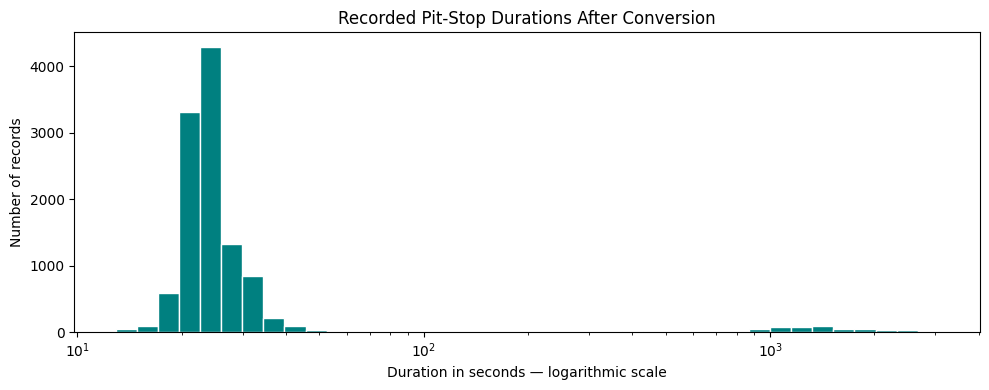

Non-positive durations: 0


,raceId,driverId,stop,lap,duration,duration_seconds
9156,1083,840,1,1,51:09.017,3069.017
9155,1083,20,1,1,51:07.301,3067.301
9157,1083,854,1,1,51:05.174,3065.174
9154,1083,825,1,1,51:03.613,3063.613
9152,1083,817,1,1,51:03.314,3063.314
9151,1083,822,1,1,50:55.732,3055.732
9147,1083,4,1,1,50:55.700,3055.700
9150,1083,849,1,1,50:51.904,3051.904
9153,1083,842,1,1,50:48.950,3048.950
9145,1083,1,1,1,50:46.888,3046.888


In [59]:
positive_durations = pit_stops_clean.loc[
    pit_stops_clean["duration_seconds"] > 0,
    "duration_seconds"
].dropna()

if not positive_durations.empty:
    minimum = positive_durations.min()
    maximum = positive_durations.max()

    bins = (
        np.geomspace(minimum, maximum, 40)
        if minimum < maximum
        else 10
    )

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.hist(
        positive_durations,
        bins=bins,
        color="teal",
        edgecolor="white"
    )

    ax.set_xscale("log")
    ax.set_title("Recorded Pit-Stop Durations After Conversion")
    ax.set_xlabel("Duration in seconds — logarithmic scale")
    ax.set_ylabel("Number of records")

    plt.tight_layout()
    plt.show()

print("Non-positive durations:",
      pit_stops_clean["duration_seconds"].le(0).sum())

display(
    pit_stops_clean.nlargest(10, "duration_seconds")[
        ["raceId", "driverId", "stop", "lap",
         "duration", "duration_seconds"]
    ]
)

### Pit-stop audit findings and deferred work

Duration parsing, milliseconds consistency, key uniqueness, and reference checks are implemented above. The eight flagged driver–race groups in the inspected dataset have unusual stop numbering. Several race 1128 records suggest swapped `stop` and `lap` values; other groups begin at stop 2. These are suspected issues, not confirmed corrections. No records were renumbered, invented, or deleted. Long durations remain pending investigation. Missing-value filling is deferred. Current-race pit-stop information must not be used for pre-race prediction.


In [60]:
pit_final_checks = pd.Series({
    "Row count unchanged": len(pit_stops_clean) == len(pit_stops),
    "No remaining placeholders": not pit_stops_clean.eq(r"\N").any().any(),
    "Key non-null": pit_stops_clean[["raceId", "driverId", "stop"]].notna().all().all(),
    "Key unique": not pit_stops_clean.duplicated(["raceId", "driverId", "stop"]).any(),
    "Duration is numeric": pd.api.types.is_numeric_dtype(pit_stops_clean["duration_seconds"]),
    "Duration missingness preserved": pit_stops_clean["duration_seconds"].isna().sum() == pit_stops["duration"].replace(r"\N", np.nan).isna().sum(),
    "Clock missingness preserved": pit_stops_clean["stop_clock_time"].isna().sum() == pit_stops["time"].replace(r"\N", np.nan).isna().sum()
})
display(pit_final_checks.to_frame("Passed"))
assert pit_final_checks.all(), "Investigate failed pit-stop checks."


,Passed
Row count unchanged,True
No remaining placeholders,True
Key non-null,True
Key unique,True
Duration is numeric,True
Duration missingness preserved,True
Clock missingness preserved,True


Mohamed 

Kareem

Hamza